# Euler System of Gas Dynamics

In [1]:
import math
import matplotlib
matplotlib.rc( 'image', cmap='jet' )
from matplotlib import pyplot
from ufl import *
from dune.generator import path
from dune.grid import structuredGrid, reader
from dune.fem.space import dgonb, finiteVolume
from dune.fem.function import gridFunction
from dune.femdg import femDGOperator
from dune.femdg.rk import femdgStepper
from dune.fem.utility import lineSample

Basic model for hyperbolic conservation law

In [2]:
class Model:
    gamma = 1.4
    # helper function
    def toPrim(U):
        v = as_vector( [U[i]/U[0] for i in range(1,3)] )
        kin = dot(v,v) * U[0] / 2
        pressure = (Model.gamma-1)*(U[3]-kin)
        return U[0], v, pressure

    # interface methods for model
    def F_c(t,x,U):
        rho, v, p = Model.toPrim(U)
        return as_matrix( [
                  [rho*v[0], rho*v[1]],
                  [rho*v[0]*v[0] + p, rho*v[0]*v[1]],
                  [rho*v[0]*v[1], rho*v[1]*v[1] + p],
                  [(U[3]+p)*v[0], (U[3]+p)*v[1]] ] )
    # simple 'outflow' boundary conditions on all boundaries
    boundary = {range(1,5): lambda t,x,U: U}

    # interface method needed for LLF and time step control
    def maxLambda(t,x,U,n):
        rho, v, p = Model.toPrim(U)
        return abs(dot(v,n)) + sqrt(Model.gamma*p/rho)

Add methods for limiting

In [3]:
def velocity(t,x,U):
    _, v ,_ = Model.toPrim(U)
    return v
def physical(t,x,U):
    rho, _, p = Model.toPrim(U)
    return conditional( rho>1e-8, conditional( p>1e-8 , 1, 0 ), 0 )
def jump(t,x,U,V):
    _,_, pL = Model.toPrim(U)
    _,_, pR = Model.toPrim(V)
    return (pL - pR)/(0.5*(pL + pR))
Model.velocity = velocity
Model.physical = physical
Model.jump     = jump

Method to evolve the solution in time

In [4]:
def evolve(space, u_h, limiter="MinMod"):
    lu_h = u_h.localFunction()
    @gridFunction(space.grid,name="rho",order=space.order)
    def rho(e,x):
        lu_h.bind(e)
        return lu_h(x)[0]
    operator = femDGOperator(Model,space, limiter=limiter) # note: that u_h.space fails since not ufl_space
    stepper  = femdgStepper(order=space.order if space.order else 2, operator=operator)
    operator.applyLimiter(u_h)
    t = 0
    saveStep = 0.1
    c = 0
    fig = pyplot.figure(figsize=(30,10))
    rho.plot(gridLines="white", figure=(fig, 131+c), colorbar=False, clim=[0.125,1])
    while t < 0.3:
        operator.setTime(t)
        t += stepper(u_h)
        if t > saveStep:
            saveStep += 0.1
            c += 1
            rho.plot(gridLines="white", figure=(fig, 131+c), colorbar=False, clim=[0.125,1])
    return lineSample(u_h,[0,0],[1,1],200)

A radial Rieman problem

In [5]:
x = SpatialCoordinate(triangle)
initial = conditional(dot(x,x)<0.1,as_vector([1,0,0,2.5]),
                                   as_vector([0.125,0,0,0.25]))

Evolve on a Cartesian grid using a second order dg method

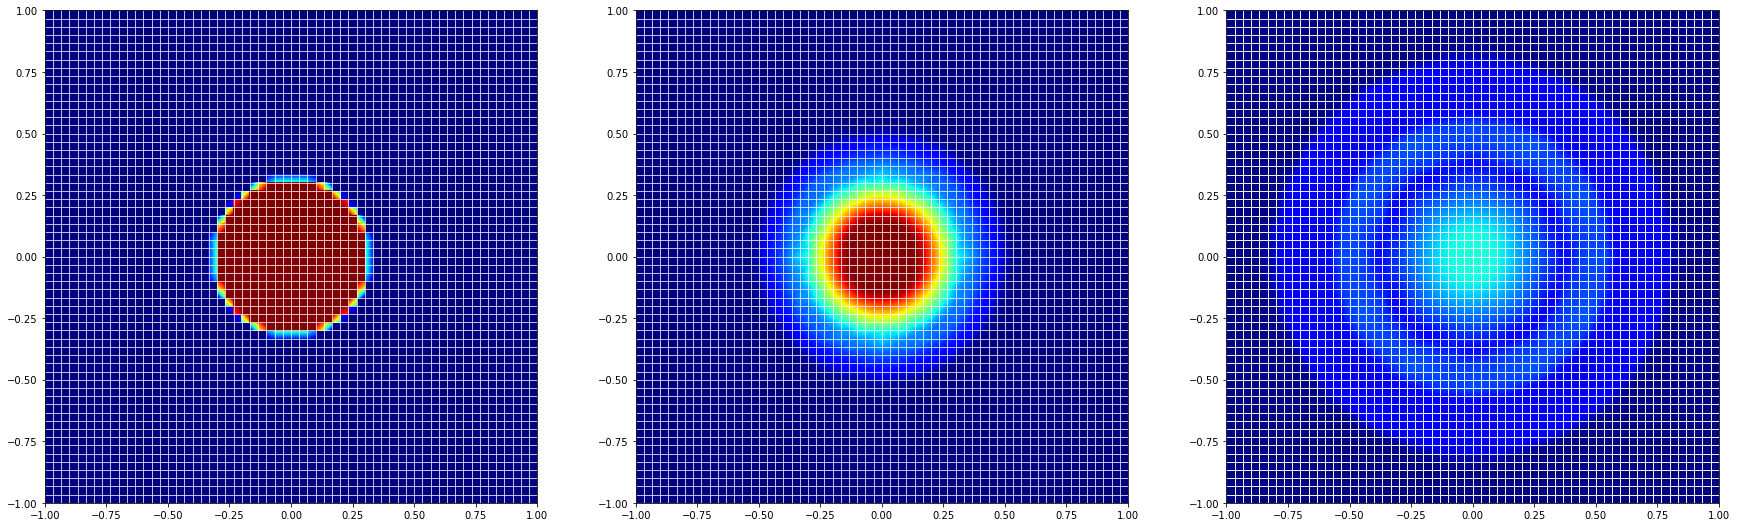

In [6]:
gridView = structuredGrid([-1,-1],[1,1],[60,60])

space = dgonb( gridView, order=2, dimRange=4)
u_h = space.interpolate( initial, name="solution")
res = [evolve(space,u_h)]

Next with a higher order finite volume scheme

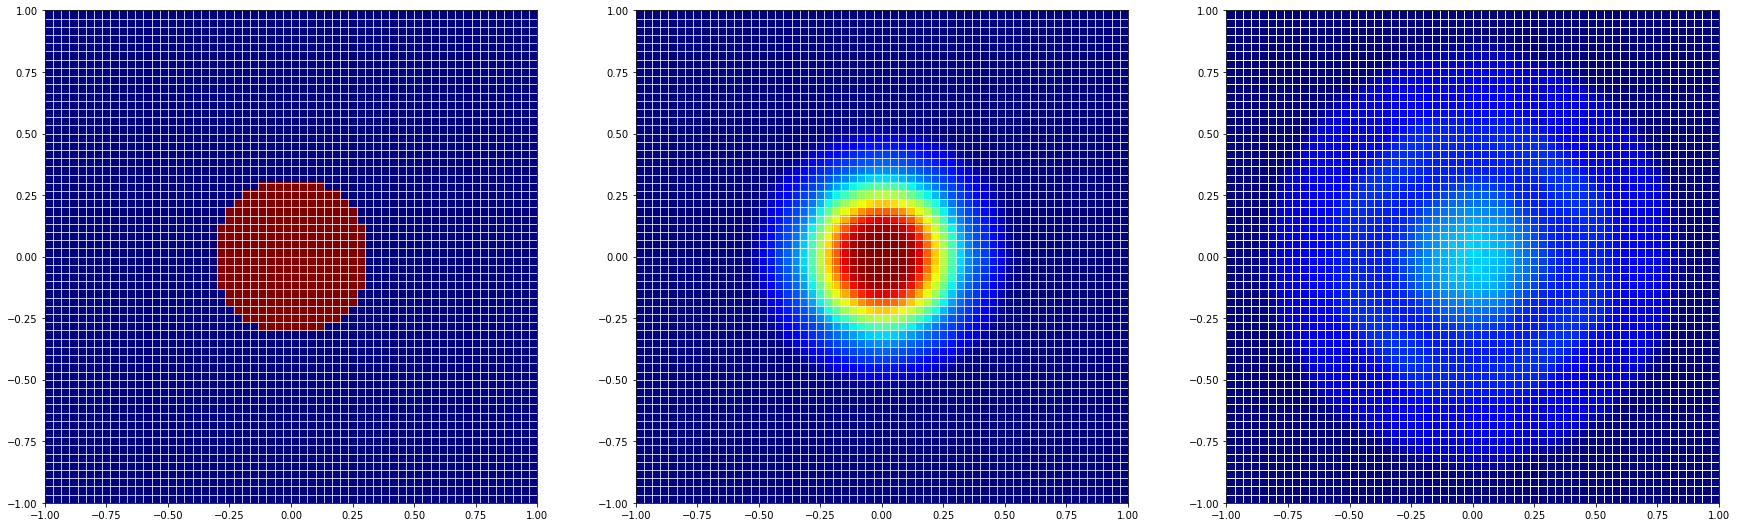

In [7]:
from dune.fem.space import finiteVolume
space = finiteVolume( gridView, dimRange=4 )
u_h = space.interpolate( initial, name="solution")
res += [evolve(space,u_h)]

Finally with the first order finite volume method

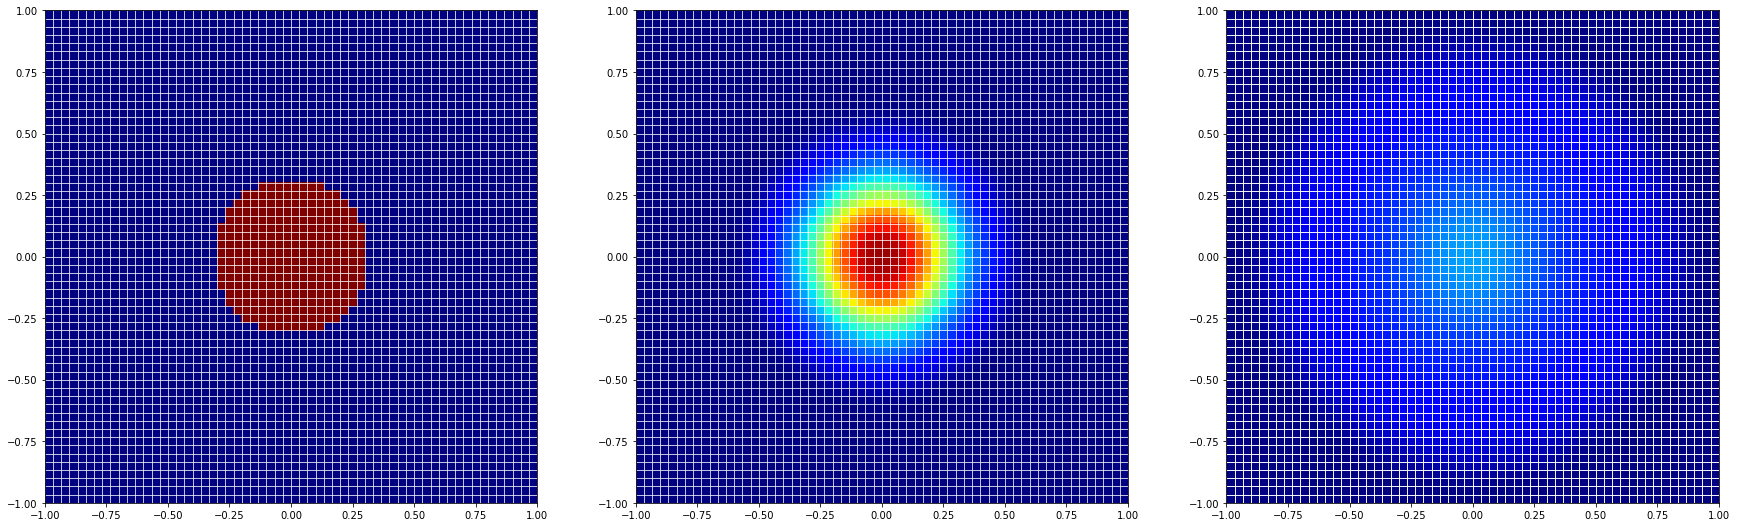

In [8]:
from dune.fem.space import finiteVolume
space = finiteVolume( gridView, dimRange=4 )
u_h = space.interpolate( initial, name="rho")
res += [evolve(space,u_h,limiter=None)]

Solutions along the diagonal

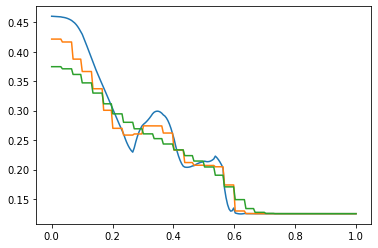

In [9]:
pyplot.plot(res[0][0],res[0][1], res[1][0],res[1][1], res[2][0],res[2][1])

Same three schemes on a polygonal grid

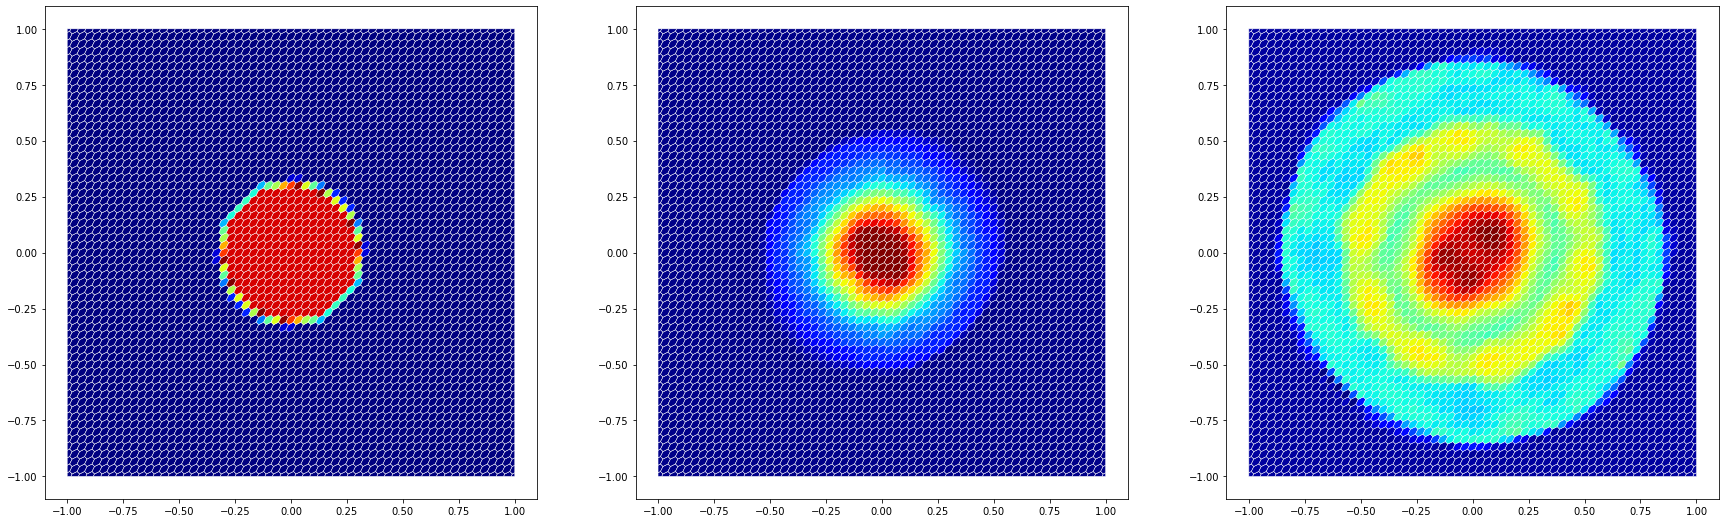

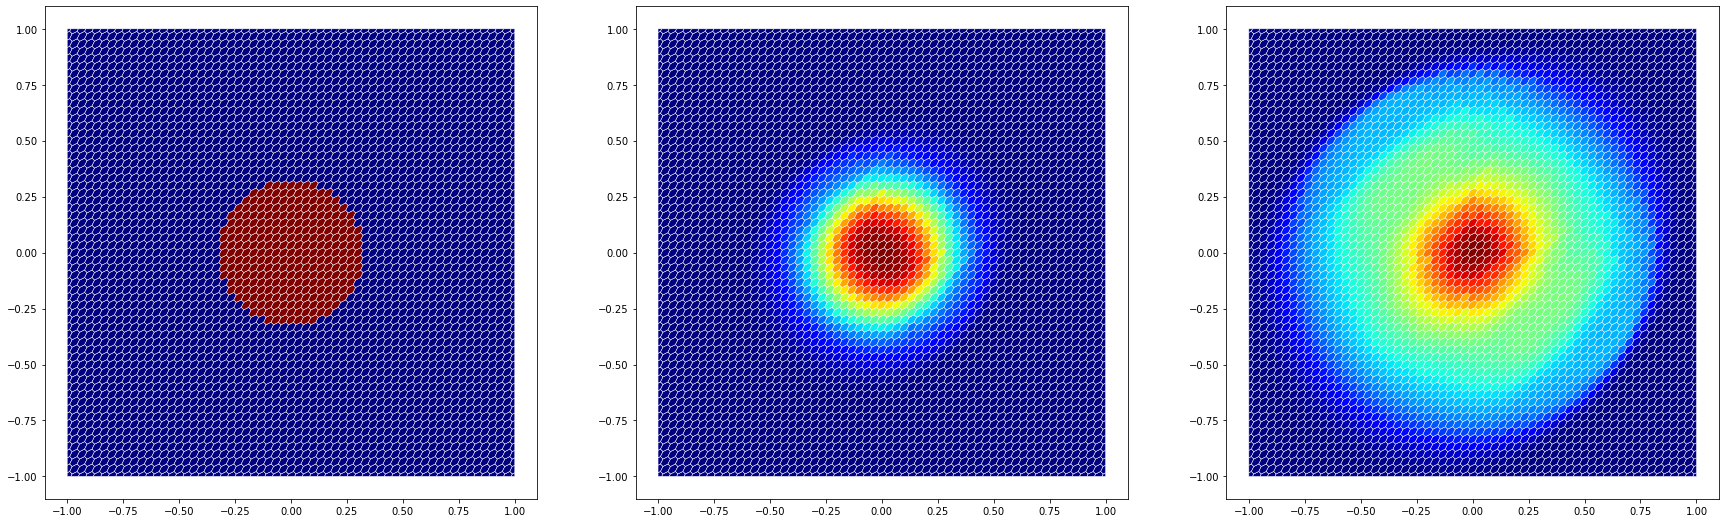

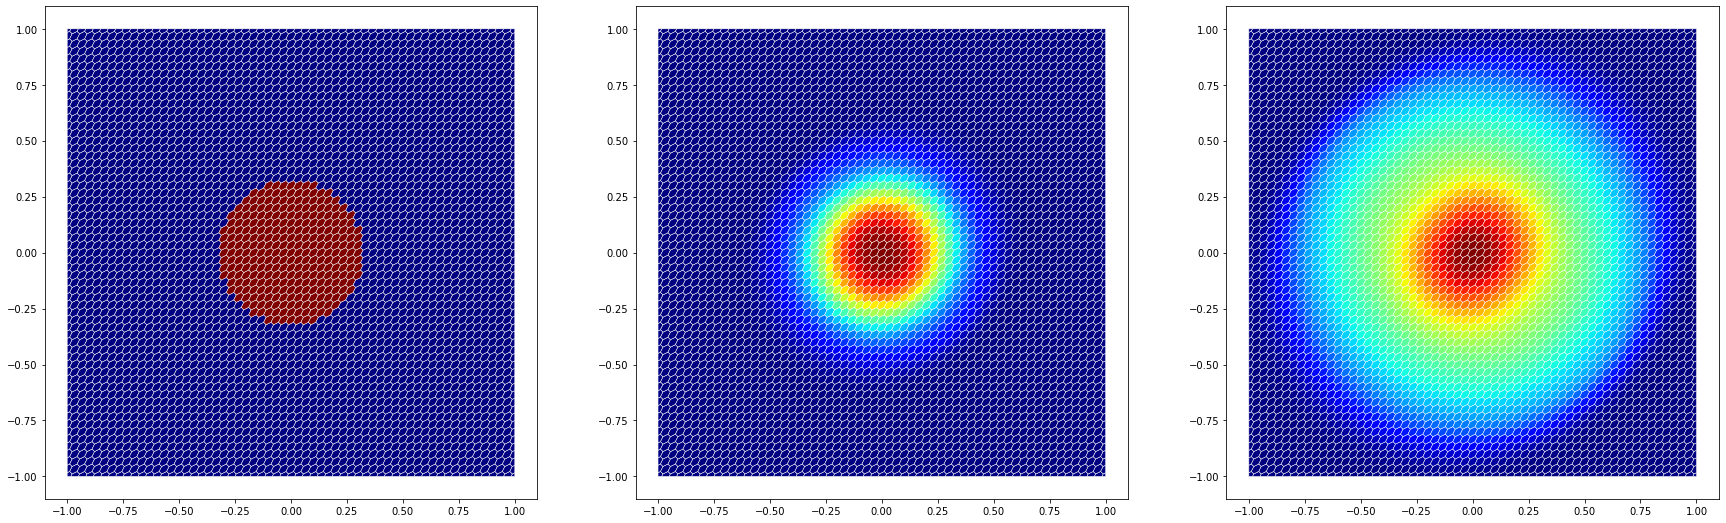

In [10]:
from dune.polygongrid import polygonGrid
domain = (reader.dgf, "triangle.dgf")
gridView = polygonGrid( domain, dualGrid=True )

space = dgonb( gridView, order=2, dimRange=4 )
u_h = space.interpolate( initial, name="solution")
res = [evolve(space,u_h)]

space = finiteVolume( gridView, dimRange=4 )
u_h = space.interpolate( initial, name="solution")
res += [evolve(space,u_h)]

space = finiteVolume( gridView, dimRange=4 )
u_h = space.interpolate( initial, name="rho")
res += [evolve(space,u_h,limiter=None)]

Solutions along the diagonal

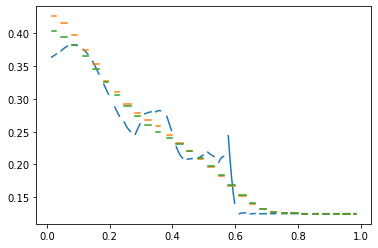

In [11]:
pyplot.plot(res[0][0],res[0][1], res[1][0],res[1][1], res[2][0],res[2][1])